In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from statsmodels.stats.proportion import proportions_ztest
from matplotlib.ticker import FuncFormatter
from scipy.stats import chisquare


In [2]:
sns.set_theme(style="whitegrid", palette="pastel") 

# Data set description and report goal

This dataset includes A/B test results of Cookie Cats to examine what happens when the first gate in the game was moved from level 30 to level 40. When a player installed the game, he or she was randomly assigned to either gate_30 or gate_40.

**Content:**

The data we have is from 90,189 players that installed the game while the AB-test was running. The variables are:

* `userid`: A unique number that identifies each player.
* `version`: Whether the player was put in the control group (gate_30 - a gate at level 30) or the group with the moved gate (gate_40 - a gate at level 40).
* `sum_gamerounds`: the number of game rounds played by the player during the first 14 days after install.
* `retention_1`: Did the player come back and play 1 day after installing?
* `retention_7`: Did the player come back and play 7 days after installing?

When a player installed the game, he or she was randomly assigned to either. 

**Goal:**

Examine if the gate placement has an impact on player retention.


# Analysis Plan

1. **Data Loading and Initial Inspection** Load this data into a structured format (like a dataframe) and perform an initial inspection to understand its structure, data types, and basic statistics. Check for missing values, duplicates, and ensure data types are appropriate for analysis.

3. **Exploratory Data Analysis (EDA):**

    * Examine the distribution of game rounds played (sum_gamerounds) for both the gate_30 (control) and gate_40 (test) groups.

    * Determine the number of players in each group.

    * Calculate the 1-day and 7-day retention rates for both groups.

4. **Hypothesis Testing:**

    * Define the null and alternative hypotheses for comparing retention rates.

    * Conduct appropriate statistical tests (e.g., Z-test or Chi-square test) to compare the retention rates between the control and test groups.

5. **Interpret Results:** Summarize the findings from the statistical analysis and draw conclusions about the A/B test.

# 1. Data Loading and Initial Inspection

In [3]:
df = pd.read_csv("cookie_cats.csv")

In [4]:
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB


In [6]:
df.describe().round(2)

,userid,sum_gamerounds
count,90189.00,90189.00
mean,4998412.23,51.87
std,2883285.61,195.05
min,116.00,0.00
25%,2512230.00,5.00
50%,4995815.00,16.00
75%,7496452.00,51.00
max,9999861.00,49854.00


There seems anomaly in data. `sum_gamerounds` is showing max value of 49854. I will calculte IQR to filter outliers out. I will take coefficient of 1,5.

#### IRQ calculation

In [7]:
coefficient = 1.5
Q1 = df['sum_gamerounds'].quantile(0.25)
Q3 = df['sum_gamerounds'].quantile(0.75)
IQR = Q3 - Q1

upper_bound_iqr = Q3 + coefficient * IQR

print(f"Q1 (25th percentile) for sum_gamerounds: {Q1}")
print(f"Q3 (75th percentile) for sum_gamerounds: {Q3}")
print(f"IQR for sum_gamerounds: {IQR}")
print(f"Upper bound for outliers: {upper_bound_iqr}")

Q1 (25th percentile) for sum_gamerounds: 5.0
Q3 (75th percentile) for sum_gamerounds: 51.0
IQR for sum_gamerounds: 46.0
Upper bound for outliers: 120.0


With calculate IRQ range how many data point I will filter out?


In [8]:
gate_30_outlier = df[(df['version'] == 'gate_30') & (df['sum_gamerounds'] > upper_bound_iqr)].shape[0]
gate_30_outlier_persentage = gate_30_outlier / df[df['version'] == 'gate_30'].shape[0]

gate_40_outlier = df[(df['version'] == 'gate_40') & (df['sum_gamerounds'] > upper_bound_iqr)].shape[0]
gate_40_outlier_persentage = gate_40_outlier / df[df['version'] == 'gate_40'].shape[0]

total_outlier = df[(df['sum_gamerounds'] > upper_bound_iqr)].shape[0]
total_outlier_persentage = total_outlier / df.shape[0]

print(f'Outlier percentage with limit {upper_bound_iqr} gate_30: {gate_30_outlier_persentage:.2%}')
print(f'Outlier percentage with limit {upper_bound_iqr} gate_40: {gate_40_outlier_persentage:.2%}')
print(f'Outlier percentage with limit {upper_bound_iqr} total: {total_outlier_persentage:.2%}')

df_filtered = df[(df['sum_gamerounds'] < upper_bound_iqr)]
df_outliers = df[df['sum_gamerounds'] >= upper_bound_iqr]

Outlier percentage with limit 120.0 gate_30: 11.32%
Outlier percentage with limit 120.0 gate_40: 11.24%
Outlier percentage with limit 120.0 total: 11.28%


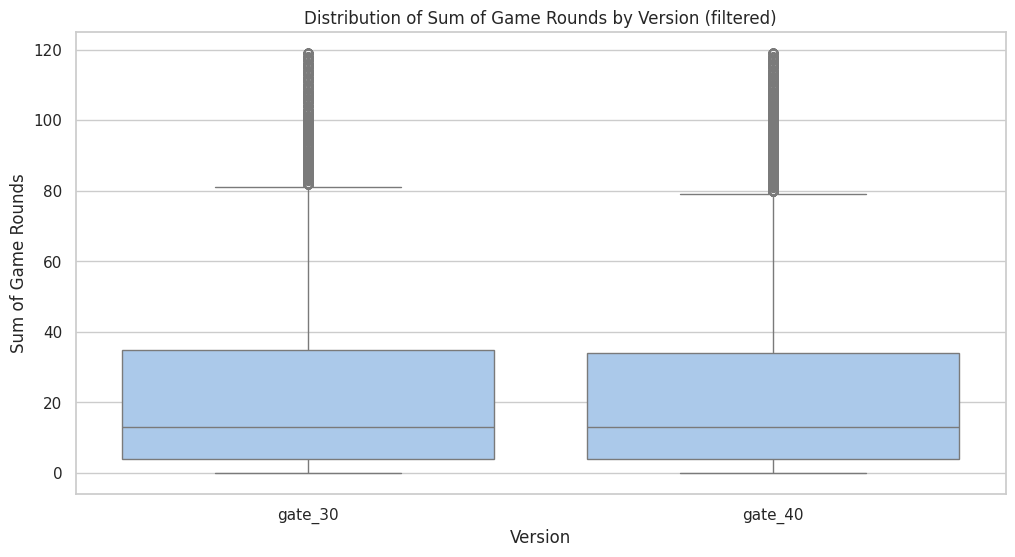

In [9]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_filtered, x='version', y='sum_gamerounds')
plt.title('Distribution of Sum of Game Rounds by Version (filtered)')
plt.xlabel('Version')
plt.ylabel('Sum of Game Rounds')
plt.show()

In [10]:
duplicate_users = df_filtered['userid'].duplicated().sum()
print(f"Number of duplicate user IDs: {duplicate_users}")

Number of duplicate user IDs: 0


# 2. Exploratory Data Analysis (EDA)

One important point to consider. This data set is about player retention, in other words about proportion of returning players to total players. `sum_gamerounds` is not a retention metric and it does not have a direct impact on retention. With that in mind my previously done filtering of outliers possible is not relevant for retention analysis, but I could remove valuable data points from metrics that is important.
I will calculate basic statistics for outliers dataset and decide if I will use full dataset for analysis.

In [11]:
players_per_group = df_outliers['version'].value_counts()
print("\nNumber of players in each group:")
print(players_per_group)

# Calculate retention rates for each group
retention_1_by_group = df_outliers.groupby('version')['retention_1'].mean()
retention_7_by_group = df_outliers.groupby('version')['retention_7'].mean()

print("\n1-day retention rate by version:")
print(retention_1_by_group.round(4))

print("\n7-day retention rate by version:")
print(retention_7_by_group.round(4))


Number of players in each group:
version
gate_40    5169
gate_30    5107
Name: count, dtype: int64

1-day retention rate by version:
version
gate_30    0.9101
gate_40    0.9069
Name: retention_1, dtype: float64

7-day retention rate by version:
version
gate_30    0.7525
gate_40    0.7512
Name: retention_7, dtype: float64


Outlier retention is quite high and possible could have impact on retention metrics.
* Retention 1:
    * gate_30 : 91,01%
    * gate_40 : 90,69%
* Retention 7:
    * gate_30 : 75,25%
    * gate_40 : 75,12%

**I will use full dataset for retention analysis.**


**Full dataset statistics:**


In [12]:
players_per_group = df['version'].value_counts()
print("\nNumber of players in each group:")
print(players_per_group)

# Calculate retention rates for each group
retention_1_by_group = df.groupby('version')['retention_1'].mean()
retention_7_by_group = df.groupby('version')['retention_7'].mean()

print("\n1-day retention rate by version:")
print(retention_1_by_group.round(4))

print("\n7-day retention rate by version:")
print(retention_7_by_group.round(4))


Number of players in each group:
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

1-day retention rate by version:
version
gate_30    0.4482
gate_40    0.4423
Name: retention_1, dtype: float64

7-day retention rate by version:
version
gate_30    0.1902
gate_40    0.1820
Name: retention_7, dtype: float64


I have generated a barplot to visually show retention rate by version

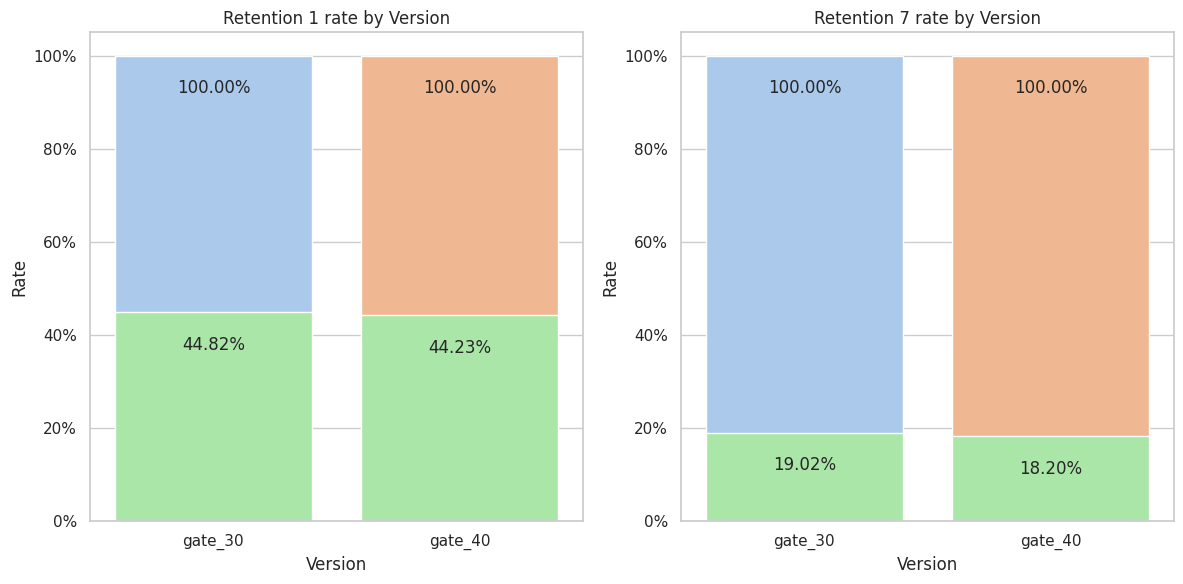

In [13]:
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
ax1 =sns.barplot(data=df, x='version', y='retention_1', estimator=(lambda x: np.size(x)/np.size(x)), hue='version', errorbar=None)
ax2 =sns.barplot(data=df, x='version', y='retention_1', estimator=np.mean, color="#A1F09F", errorbar=None)

plt.title('Retention 1 rate by Version')
plt.xlabel('Version')
plt.ylabel('Rate')
ax1.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))

for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt='{:.2%}', label_type='edge', padding=-30)


plt.subplot(1, 2, 2)
ax2 = sns.barplot(data=df, x='version', y='retention_7', estimator=(lambda x: np.size(x)/np.size(x)) , hue='version', errorbar=None)
sns.barplot(data=df, x='version', y='retention_7', estimator=np.mean , color='#A1F09F', errorbar=None)
plt.title('Retention 7 rate by Version')
plt.xlabel('Version')
plt.ylabel('Rate')
ax2.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:.0%}"))

for container in plt.gca().containers:
    plt.gca().bar_label(container, fmt='{:.2%}', label_type='edge', padding=-30)

plt.tight_layout()
plt.show()

Another point to note is that we have different payer counts in control and treatment groups. This could impact the retention rates and other metrics we are analyzing. I will check for SRM (Statistical Relevance of Metrics) to ensure that the differences we observe are meaningful.

In [14]:

observed_counts = df['version'].value_counts()
n_gate30_observed = observed_counts['gate_30']
n_gate40_observed = observed_counts['gate_40']

total_players = len(df)

# Assume an ideal 50/50 split for an A/B test
expected_proportion = 0.5
n_gate30_expected = total_players * expected_proportion
n_gate40_expected = total_players * expected_proportion

chi2_statistic, p_value = chisquare(
    f_obs=[n_gate30_observed, n_gate40_observed],
    f_exp=[n_gate30_expected, n_gate40_expected]
)

print("--- Sample Ratio Mismatch (SRM) Test ---")
print(f"Total Players: {total_players}")
print("\nObserved Counts:")
print(f"  gate_30: {n_gate30_observed}")
print(f"  gate_40: {n_gate40_observed}")
print("\nExpected Counts (assuming 50/50 split):")
print(f"  gate_30: {n_gate30_expected:.2f}")
print(f"  gate_40: {n_gate40_expected:.2f}")
print(f"\nChi-square Statistic: {chi2_statistic:.4f}")
print(f"P-value: {p_value:.4f}")


--- Sample Ratio Mismatch (SRM) Test ---
Total Players: 90189

Observed Counts:
  gate_30: 44700
  gate_40: 45489

Expected Counts (assuming 50/50 split):
  gate_30: 45094.50
  gate_40: 45094.50

Chi-square Statistic: 6.9024
P-value: 0.0086


Dataset Chi-square test for SRM P-value is 0.0086. this is lower than indusry common alpha level 0.05. We reject null hypothesis and conclude that **there is** a statistically significant Sample Ratio Mismatch (SRM). This indicates a potential issue with the randomization or data collection process. 
**Now I do not have means to 'fix" this issue, by reruning experiment or using other methods, so I will continue with analysis, but I will keep this in mind and be aware of potential impact on results.**

#### Summary

**Player Counts :**

* `gate_30` group has 45,489 players.

* `gate_40` group has 44,700 players.

**Retention Rates :**

* 1-Day Retention:

    * `gate_30`: 44,82% 
    * `gate_40`: 44,23% 

* 7-Day Retention:

    * `gate_30`: 19,02% 
    * `gate_40`: 18,2% 

The gate_30 version (where the first gate is at level 30) appears to have slightly higher 1-day and 7-day retention rates compared to the gate_40 version (where the first gate is at level 40). The next step is to perform statistical hypothesis tests to determine if these observed differences are statistically significant.

# 3. Hypothesis Testing

**Hypothesis Formulation:**
* Day 1 retention:
    * Null Hypothesis (H_0): The 1-day retention rate is the same for both `gate_30` and `gate_40` versions.
    * Alternative Hypothesis (H_1): The 1-day retention rate is different for `gate_30` and `gate_40` versions.

* Day 7 retention:
    * Null Hypothesis (H_0): The 7-day retention rate is the same for both `gate_30` and `gate_40` versions.
    * Alternative Hypothesis (H_1): The 7-day retention rate is different for `gate_30` and `gate_40` versions.


For hypothesis testing I will use Z-test for proportions, as we are comparing two proportions (retention rates) from independent samples (the two groups) and samples count is very large.

In [15]:
gate30_ret1 = df[df['version'] == 'gate_30']['retention_1']
gate40_ret1 = df[df['version'] == 'gate_40']['retention_1']

gate30_ret7 = df[df['version'] == 'gate_30']['retention_7']
gate40_ret7 = df[df['version'] == 'gate_40']['retention_7']

stats_1, p_value_1 = proportions_ztest([gate30_ret1.sum(), gate40_ret1.sum()], [len(gate30_ret1), len(gate40_ret1)], alternative='two-sided')
stats_7, p_value_7 = proportions_ztest([gate30_ret7.sum(), gate40_ret7.sum()], [len(gate30_ret7), len(gate40_ret7)], alternative='two-sided')

print("\n--- 1-Day Retention Hypothesis Test ---")
print(f"Z-statistic: {stats_1:.4f}")
print(f"P-value: {p_value_1:.4f}")

print("\n--- 7-Day Retention Hypothesis Test ---")
print(f"Z-statistic: {stats_7:.4f}")
print(f"P-value: {p_value_7:.4f}")


--- 1-Day Retention Hypothesis Test ---
Z-statistic: 1.7841
P-value: 0.0744

--- 7-Day Retention Hypothesis Test ---
Z-statistic: 3.1644
P-value: 0.0016


**1-Day Retention Hypothesis Test (Outliers Filtered):**

* Z-statistic: 1.7841

* P-value: 0.0744

    Conclusion: With a p-value of 0.0744, which is greater than the significance level of 0.05, we **fail to reject the null hypothesis**. This indicates that there is no statistically significant difference in the 1-day retention rates between the `gate_30` and `gate_40` versions. The observed difference (44,82% for gate_30 vs. 44,23% for `gate_40`) could still be due to random chance.

**7-Day Retention Hypothesis Test (Outliers Filtered):**

* Z-statistic: 3.1644

* P-value: 0.0,016

    Conclusion: With a p-value of 0.0016, which is less than the significance level of 0.05, we **reject the null hypothesis**. This confirms that there is a statistically significant difference in the 7-day retention rates between the `gate_30` and `gate_40` versions. The `gate_30` version (19,02%) still shows a statistically significant higher 7-day retention rate compared to `gate_40` (18,2%).

**Overall Interpretation:**

* There is no statistically significant difference in 1-day retention between placing the gate at level 30 or level 40.

* However, there is a statistically significant difference in 7-day retention, with `gate_30` (gate at level 30) resulting in higher long-term retention compared to `gate_40` (gate at level 40).

**This suggests that for long-term player engagement, keeping the gate at level 30 is more beneficial.**

# 4. Conclusion

My analysis focused on comparing two versions of the game: one with the first gate at level 30 (`gate_30`) and another with the first gate at level 40 (`gate_40`). The primary metrics for evaluation were 1-day and 7-day player retention rates.

**Key Findings:**

* Data Distribution: The `sum_gamerounds` data was highly right-skewed, indicating that a small percentage of players complete a very high number of game rounds. While an extreme outlier was initially identified and later it was decided to use the full dataset, the overall trends and conclusions remained consistent.

* There was statistically significant Sample Ratio Mismatch (SRM) between the two groups, which could potentially impact the results. This should be remembered when interpreting the results.

**1-Day Retention:**

* Observed Rates: `gate_30` had a 1-day retention rate of approximately 44.82% after outlier filtering and `gate_40` had 44.23% after outlier filtering.

* Statistical Significance: The hypothesis test revealed no statistically significant difference in 1-day retention rates between the `gate_30` and `gate_40` versions (p-value > 0.05). This suggests that the initial gate placement does not have a measurable impact on whether players return the very next day.

**7-Day Retention:**

* Observed Rates: `gate_30` had a 7-day retention rate of approximately 19.02% after outlier filtering and `gate_40` had 18.2% after outlier filtering.

* Statistical Significance: The hypothesis test showed a statistically significant difference in 7-day retention rates between the two versions (p-value < 0.05). 

**Overall Conclusion:**

The placement of the first gate has a significant impact on long-term player retention (7-day retention), with the `gate_30` version outperforming `gate_40`. While there is no immediate impact on short-term (1-day) retention, the data strongly suggests that players are more likely to stay engaged with the game over a week if the first gate is encountered at level 30 rather than level 40. This implies that delaying the gate until level 40 might be too frustrating or deterring for players, leading to a higher churn rate over the longer term.

**Recommendations:**

Based on these findings, I recommend the following:

* Retain the Gate at Level 30: The `gate_30` version should be implemented as the standard game experience. The A/B test provides strong statistical evidence that placing the first gate at level 30 leads to better 7-day retention. This translates to a more engaged player base over time.

* Investigate Reasons for 7-Day Drop-off in `gate_40`:

    * Conduct qualitative research (e.g., player surveys, user interviews) with players who experienced the `gate_40` version but churned. Understand their pain points or reasons for leaving around the 7-day mark.

    * Analyze in-game telemetry data for `gate_40` players leading up to the 7-day mark. Are there specific levels, features, or challenges around level 40 that might be contributing to increased churn?

* Monitor Retention Continuously: Even after implementing the `gate_30` version, continuously monitor 1-day, 7-day, and even longer-term retention metrics to ensure the decision has the desired sustained positive impact.

* Consider Further A/B Tests (Cautiously): While `gate_30` is the winner here, if future game updates involve significant changes to early-game progression or content, similar A/B tests on gate placement or other monetization/challenge points might be warranted. However, avoid testing too many variations simultaneously, and always have a clear hypothesis.

**By adhering to the `gate_30` version, the game developers are likely to cultivate a more loyal and long-term player base, which is crucial for the sustained success of the game.**